# Demo 1: one influenza model, one fit, one forecast

Does age structure buy forecast skill? Demo 1 asks that of three models of weekly
influenza hospital admissions in every US state, DC and Puerto Rico over the 2025-26
FluSight season:

| model | structure |
|---|---|
| `multi-strata-empirical` | six age groups, mixing by a measured contact matrix |
| `multi-strata-homogeneous` | the same six age groups, mixing in proportion to group size |
| `single-strata` | one population, no age structure |

This notebook builds the `multi-strata-empirical` model piece by piece in epymorph, fits it
with an ensemble Kalman filter up to one date shortly before the winter peak, and issues
one four-week forecast from there. The other two models are then built as the one change
each makes, and fitted and forecast the same way.

That is the whole workflow. The manuscript's comparison (`02-evaluation.ipynb`) repeats
the fit-then-forecast step at 25 weekly forecast dates and scores every forecast; nothing
there is new epymorph, only repetition and bookkeeping.

Everything that touches epymorph is in this notebook. Only data preparation (the frozen
CDC observations, severity, the initial conditions, the contact matrix) and plotting come
from the analysis package.

**Allow about an hour.** Each age-structured fit runs 52 jurisdictions times six age groups
at 300 realizations.

## Setup

In [1]:
import epymorph.initializer as init
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from epymorph.adrio.acs5 import PopulationByAge, PopulationByAgeTable
from epymorph.attribute import AttributeDef
from epymorph.compartment_model import edge
from epymorph.data import ipm, mm
from epymorph.data_shape import Shapes
from epymorph.forecasting.dynamic_params import (
    ExponentialTransform,
    GaussianPrior,
    OrnsteinUhlenbeck,
)
from epymorph.forecasting.ensemble_kalman_filter import EnsembleKalmanFilterSimulator
from epymorph.forecasting.filter import ModelLink, Observations
from epymorph.forecasting.forecast import ForecastSimulator
from epymorph.forecasting.likelihood import PoissonLikelihood
from epymorph.forecasting.pipeline import PipelineConfig, UnknownParam
from epymorph.geography.us_census import StateScope
from epymorph.rume import GPM, MultiStrataRUMEBuilder, SingleStrataRUME
from epymorph.time import EveryNDays, TimeFrame
from sympy import Max

# Data preparation, constants and plotting: the parts that are not epymorph.
from manuscript_analysis.demos.flu import evaluation as flu_evaluation
from manuscript_analysis.demos.flu.models import flu_season
from manuscript_analysis.plots import use_manuscript_style
from manuscript_analysis.demos.lib.params.contact_wiring import (
    contact_params,
    contact_requirements,
)
from manuscript_analysis.plots import plot_single_forecast_grid

use_manuscript_style()
COLORS = flu_evaluation.COLORS

In [2]:
# The run settings. The manuscript's runs use 300 realizations at seeds 0 and 1.
REALIZATIONS = 300
SEED = 0
WEEKS_BEFORE_PEAK = 2
HORIZON_WEEKS = 4

## 1. Where and when

The geography is a **scope**: every state, DC and Puerto Rico. The time frame is the
38-week season window, which opens ten weeks before FluSight's first forecast date.

Population by age comes from the American Community Survey through epymorph's ADRIOs,
which fetch data for a scope on demand: first the full age table, then one sum per age
group. (A Census API key must be in the repository's `.env`.)

In [3]:
season = flu_season.SEASON
STRATA = flu_season.STRATA  # six age groups, by name
NUM_STRATA = len(STRATA)

scope = StateScope.in_states(list(season.states), year=season.acs_year)
season_window = TimeFrame.of(start_date=season.start_date, duration_days=7 * season.weeks)

age_table = PopulationByAgeTable().with_context(scope=scope).inspect().result.astype(np.int64)
population_by_age = {
    name: PopulationByAge(*flu_season.AGE_ENDPOINTS[name])
    .with_context(scope=scope, params={"population_by_age_table": age_table})
    .inspect().result
    for name in STRATA
}
population_by_stratum = np.stack([population_by_age[name] for name in STRATA], axis=1)
total_population = population_by_stratum.sum(axis=1)

print(f"{scope.nodes} jurisdictions, {total_population.sum():,} people")
print(f"{season_window.start_date} to {season_window.end_date}, {season.weeks} weeks")
print("age groups:", ", ".join(name.removeprefix("age_") for name in STRATA))

52 jurisdictions, 338,156,808 people
2025-09-13 to 2026-06-05, 38 weeks
age groups: 00-04, 05-17, 18-49, 50-64, 65-74, 75-99


## 2. The disease: SIRH, once per age group

Susceptible, infectious, recovered, hospitalized: SIRH is in epymorph's library of
compartment models, so it does not need defining. The weekly hospital admissions we
observe are its `I -> H` transition.

In [4]:
for event in ipm.SIRH().events:
    print(f"{str(event.name):7s} {event.rate}")

S → I   I*S*beta/Max(1, H + I + R + S)
I → H   I*gamma*hospitalization_prob
I → R   I*gamma*(1 - hospitalization_prob)
H → R   H/hospitalization_duration
R → S   R*xi


An age-structured model is built from one copy of that model per age group, each a
**GPM** (a geo-population model: a compartment model, a movement model and an initializer
for one group). Nobody moves between states here, so the movement model is `mm.No()`.

In [5]:
SEED_RATIOS = np.array([900, 1, 200, 0], dtype=np.int64)  # S, I, R, H; a placeholder

age_groups = [
    GPM(name=name, ipm=ipm.SIRH(), mm=mm.No(), init=init.Proportional(ratios=SEED_RATIOS))
    for name in STRATA
]

## 3. How the age groups mix

Six separate SIRH models would be six separate epidemics. What joins them is
**transmission between age groups**, which a multi-strata model declares as extra edges,
`meta_edges`, alongside the six copies. The force of infection on age group `i` is

$$\lambda_i = q\,\eta_i \sum_j C_{ij}\,\frac{I_j}{N_j},$$

where $C_{ij}$ is how much group `i` contacts group `j`, `q` is transmissibility, and
`eta_i` is a per-group correction the filter estimates. These edges carry **all** of the
transmission, so each copy's own `beta` is set to zero.

In [6]:
class AgeMixing(MultiStrataRUMEBuilder):
    strata = tuple(age_groups)

    meta_requirements = (
        *contact_requirements(NUM_STRATA),  # C, entry by entry; see below
        AttributeDef(name="q", type=float, shape=Shapes.TxN),
        *[AttributeDef(name=f"eta_{i}", type=float, shape=Shapes.TxN)
          for i in range(NUM_STRATA)],
    )

    def meta_edges(self, symbols):
        compartments = [symbols.strata_compartments(name) for name in STRATA]
        populations = [Max(1, sum(group)) for group in compartments]
        (q,) = symbols.requirements("q")

        edges = []
        for i in range(NUM_STRATA):
            S_i, I_i, _, _ = compartments[i]
            (eta_i,) = symbols.requirements(f"eta_{i}")
            rates = []
            for j in range(NUM_STRATA):
                (c_ij,) = symbols.requirements(f"contact_{i}_{j}")
                _, I_j, _, _ = compartments[j]
                rates.append(q * eta_i * c_ij * S_i * I_j / populations[j])
            edges.append(edge(S_i, I_i, rate=sum(rates)))
        return edges

The contact matrix $C$ is the Mistry et al. matrix for the United States, projected onto
each state's own age distribution and normalized. That is data preparation, so it lives
in the analysis package. One wrinkle is worth knowing: epymorph has no data shape for a
per-state matrix yet, so `contact_params` supplies the 36 entries as 36 parameters.

Below, the empirical matrix for one state beside the **homogeneous** one, where contact is
simply in proportion to each group's size. That second matrix is the only thing that
distinguishes the `multi-strata-homogeneous` model.

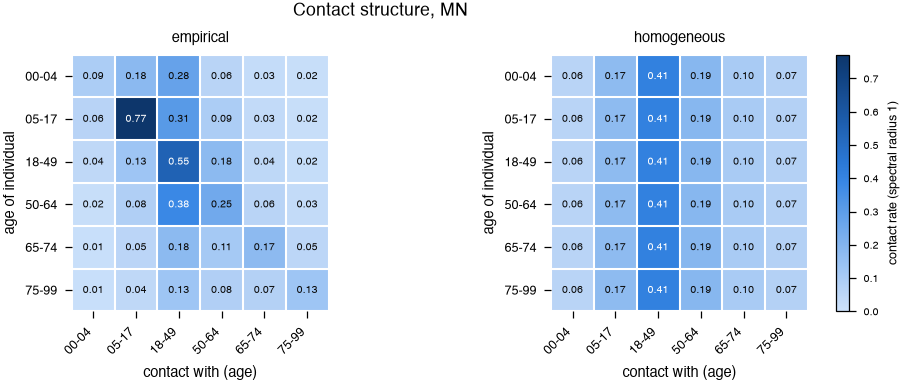

In [7]:
fig = flu_evaluation.figure_contact_structures(flu_evaluation.FOCUS_STATE)
plt.show()

## 4. Parameters: fixed and estimated

Recovery, waning and hospital stay are fixed; severity is fixed per age group from CDC's
case-hospitalization ratios. The filter estimates seven parameters per state, all on the
log scale and all changing over time: transmissibility `q`, and one correction `eta_i`
per age group, centred on no correction. Each has:

- a **prior**: what we believe before any data, a normal distribution on the log scale;
- **dynamics**: how it may drift between observations, an Ornstein-Uhlenbeck process that
  wanders but is pulled back towards its mean.

`ExponentialTransform("log_q")` connects the two: the model's `q` is `exp(log_q)`, and
`log_q` is what the filter estimates.

In [8]:
def stratified_params(mixing):
    return {
        # The meta edges carry all transmission, so each copy's own beta is zero.
        "*::ipm::beta": 0.0,
        "*::ipm::gamma": flu_season.GAMMA,  # 1 / 5-day infectious period
        "*::ipm::xi": flu_season.XI,  # 1 / 365-day immunity
        "*::ipm::hospitalization_duration": flu_season.H_DURATION,
        **{f"gpm:{name}::*::population": population_by_age[name] for name in STRATA},
        **{
            f"gpm:{name}::ipm::hospitalization_prob": flu_season.hospitalization_prob()[name]
            for name in STRATA
        },
        "meta::ipm::q": ExponentialTransform("log_q"),
        **{f"meta::ipm::eta_{i}": ExponentialTransform(f"log_eta_{i}")
           for i in range(NUM_STRATA)},
        "meta::ipm::population_by_stratum": population_by_stratum,
        **contact_params(
            flu_season.contact_source(),
            mixing=mixing,
            population_attribute=flu_season.population_attribute(),
        ),
    }


def estimated(mean, prior_sd, damping, ou_sd):
    return UnknownParam(
        prior=GaussianPrior(mean=mean, standard_deviation=prior_sd),
        dynamics=OrnsteinUhlenbeck(damping=damping, mean=mean, standard_deviation=ou_sd),
    )


log_q = estimated(flu_season.LOG_Q_MEAN, flu_season.Q_PRIOR_SD,
                  flu_season.Q_DAMPING, flu_season.Q_OU_SD)
stratified_unknowns = {
    "meta::ipm::log_q": log_q,
    **{
        f"meta::ipm::log_eta_{i}": estimated(
            0.0, flu_season.ETA_PRIOR_SD, flu_season.ETA_DAMPING, flu_season.ETA_OU_SD
        )
        for i in range(NUM_STRATA)
    },
}

flu_season.parameter_table()

,parameter,value,unit,description
0,gamma,0.2,1/day,"recovery rate, 5-day infectious period"
1,xi,0.00273973,1/day,"waning rate, 1-year immunity"
2,hospitalization_duration,5,days,mean stay
3,q_mean,0.25,1/day,"prior mean transmissibility, R0 * gamma"
4,symptomatic_fraction,0.6667,-,infections that become symptomatic
5,elderly_rate_ratio,2.71,-,75+ to 65-74 admissions per capita
6,infectious_days,5,days,seeding window
7,seed_log_sd,0.5493,log units,seed spread
8,floored_spread_multiplier,2,-,extra seed spread where week-0 admissions were...
9,immune_low,0.25,-,"prior immunity, lower bound"


## 5. When to forecast from

The forecast is issued two weeks before national admissions peaked, so its four weeks
straddle the peak: the hardest stretch of a season to forecast. The filter assimilates
every week before that date and nothing after it.

In [9]:
observed = flu_season.observations()  # the frozen CDC data: (weeks, jurisdictions, ages)

peak_week = int(np.argmax(observed.total.sum(axis=1)))
origin_week = peak_week - WEEKS_BEFORE_PEAK
fit_window = TimeFrame.of(start_date=season.start_date, duration_days=7 * origin_week)

print(f"national admissions peaked in the week labelled {observed.dates[peak_week]:%Y-%m-%d}")
print(f"fit {fit_window.start_date} to {fit_window.end_date} ({origin_week} weeks), "
      f"then forecast {HORIZON_WEEKS} weeks")

national admissions peaked in the week labelled 2026-01-03
fit 2025-09-13 to 2025-12-19 (14 weeks), then forecast 4 weeks


## 6. The model

A **RUME** (runnable modeling experiment) puts the pieces together: here the age-mixing
builder, given the scope, the time frame and the parameters.

The initializer in each GPM is a placeholder. The filter is handed its starting
compartments directly, one draw per realization, backed out of each state's first week of
admissions; how those are drawn is data preparation, so it lives in `flu_season`.

In [10]:
empirical_model = AgeMixing().build(
    scope=scope, time_frame=fit_window, params=stratified_params("empirical")
)
print(f"{len(empirical_model.ipm.compartments)} compartments and "
      f"{len(empirical_model.ipm.events)} transitions per jurisdiction")

24 compartments and 36 transitions per jurisdiction


### How the data meet the model

`Observations` says what the model's output is compared with, and how. The `ModelLink`
selects the matching model quantities: every jurisdiction, the whole time frame summed
into seven-day weeks, and the `I -> H` transition of every age group, one observed
channel each. The likelihood scores the observed counts against the model's.

In [11]:
def observations_for(model, source, transitions):
    return Observations(
        source=source,
        model_link=ModelLink(
            geo=model.scope.select.all(),
            time=model.time_frame.select.all().group(EveryNDays(7)).agg("sum"),
            quantity=model.ipm.select.events(transitions),
        ),
        likelihood=PoissonLikelihood(),
    )


empirical_observations = observations_for(
    empirical_model, observed.by_age_source, "I_*->H_*"
)

## 7. Fit: the ensemble Kalman filter

The filter runs the model forward one week at a time as an ensemble of realizations, each
with its own parameter values drawn from the prior. At every observed week it nudges each
realization's compartments and parameters towards the data, in proportion to how
uncertain the ensemble is relative to the observation. What comes out is a fitted ensemble:
the state of the epidemic, and the estimated parameters, as of the last observed week.

In [12]:
def fit(model, observations, unknowns, initial_values_factory):
    config = PipelineConfig.from_rume(
        rume=model,
        num_realizations=REALIZATIONS,
        unknown_params=unknowns,
        initial_values=initial_values_factory(REALIZATIONS, np.random.default_rng(SEED)),
    )
    filter_simulator = EnsembleKalmanFilterSimulator(config=config, observations=observations)
    return filter_simulator.run(rng=np.random.default_rng(SEED))


empirical_fit = fit(
    empirical_model, empirical_observations, stratified_unknowns,
    flu_season.stratified_initial_values,
)

## 8. Forecast

A forecast is the fitted ensemble run forward with no more data. `PipelineConfig.from_output`
continues from where the filter stopped; `extend_duration` is how far. Demo 1 keeps the
filter's own parameter dynamics over the forecast.

In [13]:
def forecast(fitted):
    config = PipelineConfig.from_output(fitted, extend_duration=7 * HORIZON_WEEKS)
    return ForecastSimulator(config).run(rng=np.random.default_rng(SEED + 1))


empirical_forecast = forecast(empirical_fit)
print(f"events {empirical_forecast.events.shape} "
      "(realizations, days, jurisdictions, transitions)")

events (300, 28, 52, 36) (realizations, days, jurisdictions, transitions)


### Reading the forecast out

The result holds every compartment and every transition, per realization, day and
jurisdiction. Weekly admissions in each age group are the weekly sum of that group's
`I -> H` transition. All three models are scored on **total** admissions, so the age
groups are summed **within each realization**, and only then summarized into quantiles.
Quantiles do not add: the sum of six age groups' medians is not the median of the total.

In [14]:
LEVELS = (0.025, 0.25, 0.5, 0.75, 0.975)


def weekly_admissions(result, model, transitions):
    # (realizations, weeks, jurisdictions, groups): each group's weekly I -> H.
    names = [str(e.name) for e in model.ipm.events]
    indices = [names.index(t) for t in transitions]
    realizations, days, nodes, _ = result.events.shape
    weeks = days // 7
    per_day = result.events[..., indices]
    return per_day.reshape(realizations, weeks, 7, nodes, len(indices)).sum(axis=2)


AGE_TRANSITIONS = [f"I_{name} → H_{name}" for name in STRATA]


def quantiles(ensemble):
    return {level: np.quantile(ensemble, level, axis=0) for level in LEVELS}


empirical_by_age = weekly_admissions(empirical_forecast, empirical_model, AGE_TRANSITIONS)
empirical_total = quantiles(empirical_by_age.sum(axis=-1))  # level -> (weeks, jurisdictions)

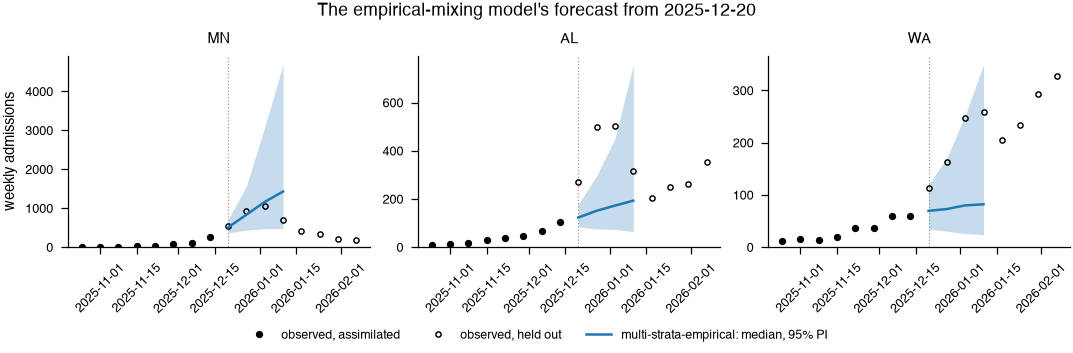

In [15]:
STATES = list(flu_evaluation.REFERENCE_STATES[:3])
LABELS = dict(zip(scope.labels, range(scope.nodes)))  # postal code -> node index
WINDOW = slice(max(origin_week - 8, 0), origin_week + HORIZON_WEEKS + 4)
dates = observed.dates


def panels(forecasts):
    # One row, one column per state: total weekly admissions.
    row = []
    for state in STATES:
        node = LABELS[state]
        row.append({
            "title": state,
            "dates": dates[WINDOW],
            "observed": observed.total[WINDOW, node],
            "origin": dates[origin_week],
            "forecast_dates": dates[origin_week:origin_week + HORIZON_WEEKS],
            "forecasts": {
                label: {level: values[:, node] for level, values in result.items()}
                for label, result in forecasts.items()
            },
        })
    return [row]


fig, _ = plot_single_forecast_grid(
    panels({"multi-strata-empirical": empirical_total}), colors=COLORS,
    ylabels="weekly admissions",
    title=f"The empirical-mixing model's forecast from {dates[origin_week]:%Y-%m-%d}",
)
plt.show()

The same forecast, before the age groups are summed: this is what age structure adds, a
forecast for each age group in its own right.

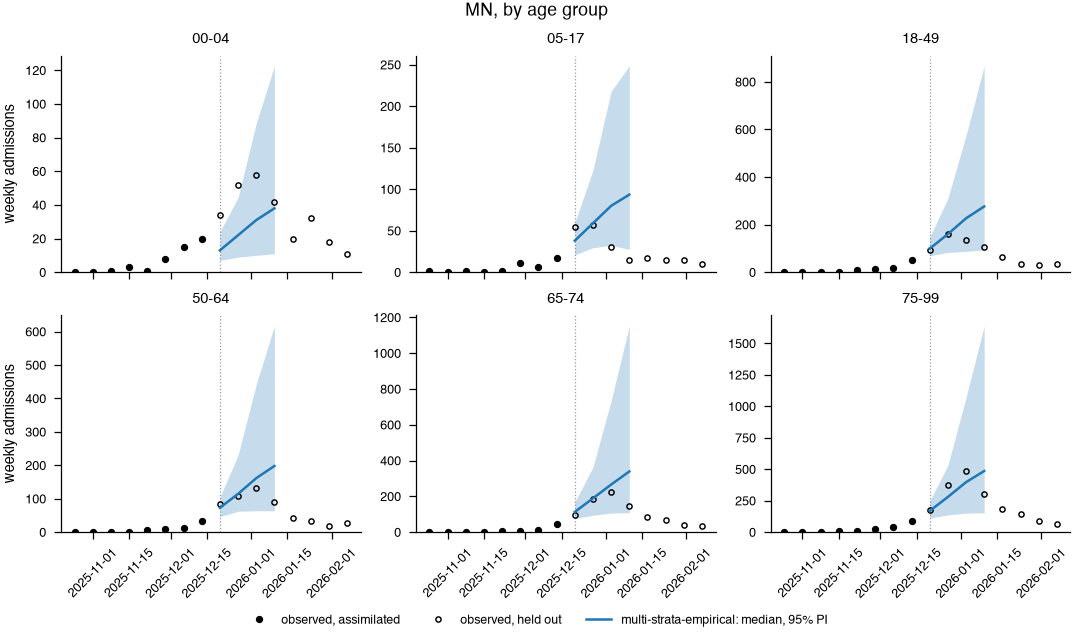

In [16]:
focus = LABELS[flu_evaluation.FOCUS_STATE]
by_age = quantiles(empirical_by_age)  # level -> (weeks, jurisdictions, ages)
age_panels = [{
    "title": name.removeprefix("age_"),
    "dates": dates[WINDOW],
    "observed": observed.by_age[WINDOW, focus, a],
    "origin": dates[origin_week],
    "forecast_dates": dates[origin_week:origin_week + HORIZON_WEEKS],
    "forecasts": {
        "multi-strata-empirical": {
            level: values[:, focus, a] for level, values in by_age.items()
        },
    },
} for a, name in enumerate(STRATA)]

fig, _ = plot_single_forecast_grid(
    [age_panels[:3], age_panels[3:]], colors=COLORS, ylabels="weekly admissions",
    title=f"{flu_evaluation.FOCUS_STATE}, by age group",
)
plt.show()

## 9. The other two models: one change each

The comparison rests on the models differing only in what the question is about, so each
of the other two is the empirical-mixing model with one thing changed.

**`multi-strata-homogeneous`** keeps the six age groups and replaces the measured contact
matrix with contact in proportion to group size. Everything else is identical, down to
the parameters, priors and initial conditions.

In [17]:
homogeneous_model = AgeMixing().build(
    scope=scope,
    time_frame=fit_window,
    params=stratified_params("homogeneous"),  # was "empirical"
)

**`single-strata`** removes the age groups. It is SIRH on each jurisdiction's whole
population, so transmission is a single `beta`, which is `q` (the contact matrix of one
group is just `[1]`). Its severity is the population-weighted average of the six, so it
starts at the same level, and it is fitted to the same total admissions.

In [18]:
single_model = SingleStrataRUME.build(
    ipm=ipm.SIRH(),
    mm=mm.No(),
    init=init.Proportional(ratios=SEED_RATIOS),
    scope=scope,
    time_frame=fit_window,
    params={
        "ipm::beta": ExponentialTransform("log_q"),  # one group, so beta is q
        "ipm::gamma": flu_season.GAMMA,
        "ipm::xi": flu_season.XI,
        "ipm::hospitalization_prob": flu_season.hospitalization_prob_total(),
        "ipm::hospitalization_duration": flu_season.H_DURATION,
        "*::population": total_population,
    },
)
single_unknowns = {"ipm::log_q": log_q}  # no age groups, so no eta

The same calls fit and forecast both.

In [19]:
homogeneous_fit = fit(
    homogeneous_model,
    observations_for(homogeneous_model, observed.by_age_source, "I_*->H_*"),
    stratified_unknowns,
    flu_season.stratified_initial_values,
)
single_fit = fit(
    single_model,
    observations_for(single_model, observed.total_source, "I->H"),
    single_unknowns,
    flu_season.unstratified_initial_values,
)

homogeneous_total = quantiles(
    weekly_admissions(forecast(homogeneous_fit), homogeneous_model, AGE_TRANSITIONS)
    .sum(axis=-1)
)
single_total = quantiles(
    weekly_admissions(forecast(single_fit), single_model, ["I → H"]).sum(axis=-1)
)

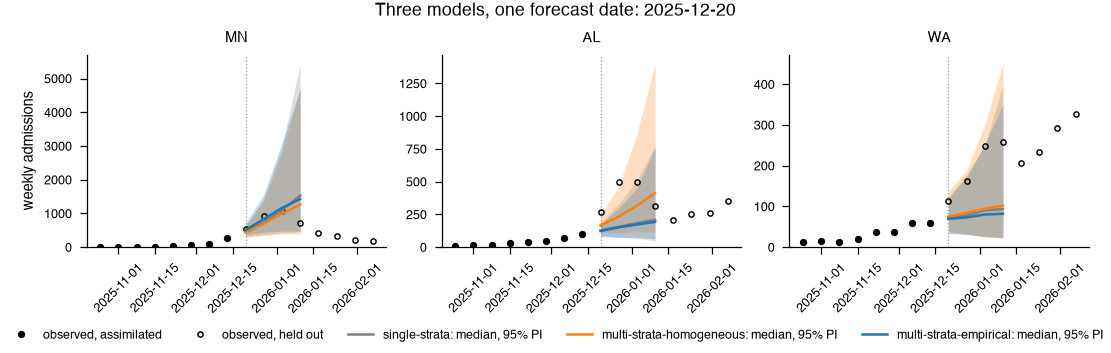

In [20]:
fig, _ = plot_single_forecast_grid(
    panels({
        "single-strata": single_total,
        "multi-strata-homogeneous": homogeneous_total,
        "multi-strata-empirical": empirical_total,
    }),
    colors=COLORS, ylabels="weekly admissions",
    title=f"Three models, one forecast date: {dates[origin_week]:%Y-%m-%d}",
)
plt.show()

### What the filter learned

The estimated transmissibility `q` as of each day of the fit, the median across
realizations. The filter has no access to anything but the observations, so this is each
model's own account of how transmission changed through the autumn.

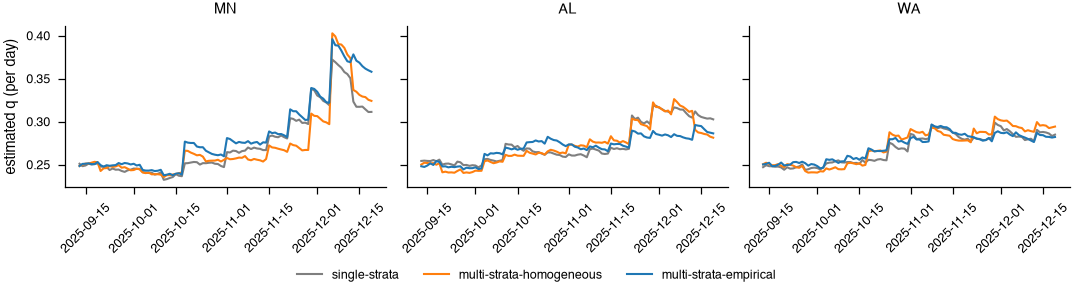

In [21]:
fig, axs = plt.subplots(1, len(STATES), figsize=(7.2, 2.0), sharey=True,
                        layout="constrained")
fit_days = pd.date_range(fit_window.start_date, periods=fit_window.days)

for label, fitted in (("single-strata", single_fit),
                      ("multi-strata-homogeneous", homogeneous_fit),
                      ("multi-strata-empirical", empirical_fit)):
    key = next(k for k in fitted.estimated_params if str(k).endswith("log_q"))
    q = np.exp(fitted.estimated_params[key])  # (realizations, days, jurisdictions)
    for ax, state in zip(axs, STATES):
        ax.plot(fit_days, np.median(q[:, :, LABELS[state]], axis=0),
                color=COLORS[label], label=label)
        ax.set_title(state)
        ax.tick_params(axis="x", labelrotation=45)

axs[0].set_ylabel("estimated q (per day)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
plt.show()

## 10. Is this the model the manuscript ran?

Writing the models out here means there are two copies of each: this notebook's, and the
ones in `manuscript_analysis.demos.flu.models` that produced the manuscript's numbers.
This check builds both over the first week of the season, with the same seed and a small
ensemble, and requires their filter output to be **identical**: every compartment and
every estimated parameter, in every realization.

If someone changes one copy and not the other, this cell fails.

In [22]:
import dataclasses

from manuscript_analysis.demos.flu.models import multi_strata_flu, single_strata

CHECK_REALIZATIONS, CHECK_WEEKS = 50, 1
check_window = TimeFrame.of(start_date=season.start_date, duration_days=7 * CHECK_WEEKS)


def short_filter(rume, unknowns, observations, initial_values_factory):
    return EnsembleKalmanFilterSimulator(
        config=PipelineConfig.from_rume(
            rume=dataclasses.replace(rume, time_frame=check_window),
            num_realizations=CHECK_REALIZATIONS,
            unknown_params=unknowns,
            initial_values=initial_values_factory(
                CHECK_REALIZATIONS, np.random.default_rng(SEED)
            ),
        ),
        observations=observations,
    ).run(rng=np.random.default_rng(SEED))


def same_output(a, b):
    params_a = [a.estimated_params[k] for k in sorted(a.estimated_params, key=str)]
    params_b = [b.estimated_params[k] for k in sorted(b.estimated_params, key=str)]
    return np.array_equal(a.compartments, b.compartments) and all(
        np.array_equal(x, y) for x, y in zip(params_a, params_b, strict=True)
    )


pairs = {
    "empirical": (empirical_model, stratified_unknowns, observed.by_age_source,
                  "I_*->H_*", flu_season.stratified_initial_values,
                  multi_strata_flu.empirical),
    "homogeneous": (homogeneous_model, stratified_unknowns, observed.by_age_source,
                    "I_*->H_*", flu_season.stratified_initial_values,
                    multi_strata_flu.homogeneous),
    "single": (single_model, single_unknowns, observed.total_source, "I->H",
               flu_season.unstratified_initial_values, single_strata.model),
}
for name, (ours, unknowns, source, transitions, initial_values_factory, theirs) in (
    pairs.items()
):
    ours_check = dataclasses.replace(ours, time_frame=check_window)
    mine = short_filter(
        ours, unknowns, observations_for(ours_check, source, transitions),
        initial_values_factory,
    )
    module = short_filter(
        theirs.rume, theirs.unknown_params,
        Observations(
            source=theirs.observations_source(),
            model_link=theirs.observations.model_link,
            likelihood=theirs.observations.likelihood,
        ),
        theirs.initial_values_factory,
    )
    assert same_output(mine, module), f"{name}: this notebook's model has drifted"
    print(f"{name:12s} identical to manuscript_analysis's {theirs.name!r} model")

empirical    identical to manuscript_analysis's 'multi-strata-empirical' model


homogeneous  identical to manuscript_analysis's 'multi-strata-homogeneous' model


single       identical to manuscript_analysis's 'single-strata' model
